##### Copyright 2021 The TensorFlow Authors.

In [ ]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Generate music with an RNN

<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://www.tensorflow.org/tutorials/audio/music_generation"><img src="https://www.tensorflow.org/images/tf_logo_32px.png" />View on TensorFlow.org</a>
  </td>
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/audio/music_generation.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/tensorflow/docs/blob/master/site/en/tutorials/audio/music_generation.ipynb"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View source on GitHub</a>
  </td>
  <td>
    <a href="https://storage.googleapis.com/tensorflow_docs/docs/site/en/tutorials/audio/music_generation.ipynb"><img src="https://www.tensorflow.org/images/download_logo_32px.png" />Download notebook</a>
  </td>
</table>

This tutorial shows you how to generate musical notes using a simple recurrent neural network (RNN). You will train a model using a collection of piano MIDI files from the [MAESTRO dataset](https://magenta.tensorflow.org/datasets/maestro). Given a sequence of notes, your model will learn to predict the next note in the sequence. You can generate longer sequences of notes by calling the model repeatedly.

This tutorial contains complete code to parse and create MIDI files. You can learn more about how RNNs work by visiting the [Text generation with an RNN](https://www.tensorflow.org/text/tutorials/text_generation) tutorial.

## Setup

###1. Устанавливаем зависимости

In [6]:
!sudo apt install -y fluidsynth

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core fluid-soundfont-gm gsettings-desktop-schemas
  libatk-bridge2.0-0t64 libatk1.0-0t64 libatspi2.0-0t64 libb2-1
  libdouble-conversion3 libevdev2 libfluidsynth3 libgtk-3-0t64 libgtk-3-bin
  libgtk-3-common libgudev-1.0-0 libinput-bin libinput10 libinstpatch-1.0-2
  libmd4c0 libmtdev1t64 libpipewire-0.3-0t64 libpipewire-0.3-common
  libproxy1v5 libqt6core6t64 libqt6dbus6t64 libqt6gui6t64 libqt6network6t64
  libqt6opengl6t64 libqt6qml6 libqt6qmlmodels6 libqt6quick6
  libqt6waylandclient6 libqt6waylandcompositor6
  libqt6waylandeglclienthwintegration6
  libqt6waylandeglcompositorhwintegration6 libqt6widgets6t64
  libqt6wlshellintegration6 librsvg2-common libspa-0.2-modules libts0t64
  libwacom-common libwacom9 libwayland-server0 libwebrtc-audio-processing1
  libxcb-icccm4 libxcb-image0 libxcb-keysyms1 libxcb-render

In [7]:
!pip install --upgrade pyfluidsynth

In [8]:
!pip install pretty_midi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 27.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pretty_midi]


###2. Импортируем и настраиваем

In [9]:
import collections
import glob
import numpy as np
import pandas as pd
import pathlib
import pretty_midi
import seaborn as sns
import tensorflow as tf
import fluidsynth
import zipfile
from typing import Optional
from IPython import display
from matplotlib import pyplot as plt

In [10]:
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

# Sampling rate for audio playback
_SAMPLING_RATE = 16000

###3. Скачиваем рок-датасета с Hugging Face

In [11]:
data_dir = pathlib.Path('data/rock_midi')
if not data_dir.exists():
    tf.keras.utils.get_file(
        'rock_midi_files.zip',
        origin='https://huggingface.co/datasets/rasta3050/mididataset/resolve/main/rock_midi_files.zip',
        extract=False,
        cache_dir='.', cache_subdir='data',
    )
    with zipfile.ZipFile('data/rock_midi_files.zip') as zf:
        zf.extractall('data/rock_midi')

filenames = sorted(glob.glob('data/rock_midi/**/*.mid*', recursive=True))
print('Number of files:', len(filenames))

23116634/23116634 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Number of files: 2414


The dataset contains about 2,414 MIDI files.

In [12]:
filenames = glob.glob('data/**/*.mid*', recursive=True)
print('Number of files:', len(filenames))

Number of files: 2414


###4. Разбираем MIDI-файл

First, use ```pretty_midi``` to parse a single MIDI file and inspect the format of the notes. If you would like to download the MIDI file below to play on your computer, you can do so in colab by writing ```files.download(sample_file)```.


In [13]:
sample_file = filenames[1]
print(sample_file)

data/rock_midi/rock_midi_files/2593.mid


Generate a `PrettyMIDI` object for the sample MIDI file.

In [14]:
pm = pretty_midi.PrettyMIDI(sample_file)

Play the sample file. The playback widget may take several seconds to load.

In [15]:
def display_audio(pm: pretty_midi.PrettyMIDI, seconds=30):
  waveform = pm.fluidsynth(fs=_SAMPLING_RATE)
  # Take a sample of the generated waveform to mitigate kernel resets
  waveform_short = waveform[:seconds*_SAMPLING_RATE]
  return display.Audio(waveform_short, rate=_SAMPLING_RATE)

In [16]:
display_audio(pm)

Do some inspection on the MIDI file. What kinds of instruments are used?

In [17]:
print('Number of instruments:', len(pm.instruments))
instrument = pm.instruments[0]
instrument_name = pretty_midi.program_to_instrument_name(instrument.program)
print('Instrument name:', instrument_name)

Number of instruments: 9
Instrument name: Sitar


###5. Извлекаем ноты

In [18]:
# выбираем самый «насыщенный» недрамовый канал (обычно гитара или бас)
def pick_instrument(pm: pretty_midi.PrettyMIDI) -> pretty_midi.Instrument:
    candidates = [ins for ins in pm.instruments if not ins.is_drum and ins.notes]
    if candidates:
        return max(candidates, key=lambda ins: len(ins.notes))
    return max(pm.instruments, key=lambda ins: len(ins.notes))

In [19]:
def midi_to_notes(midi_file: str) -> Optional[pd.DataFrame]:
    try:
        pm = pretty_midi.PrettyMIDI(midi_file)
        instrument = pick_instrument(pm)
        notes = collections.defaultdict(list)
        sorted_notes = sorted(instrument.notes, key=lambda n: n.start)
        if len(sorted_notes) < 20:   # отсекаем пустые и битые файлы
            return None
        prev_start = sorted_notes[0].start
        for note in sorted_notes:
            start, end = note.start, note.end
            notes['pitch'].append(note.pitch)
            notes['start'].append(start)
            notes['end'].append(end)
            notes['step'].append(start - prev_start)
            notes['duration'].append(end - start)
            prev_start = start
        return pd.DataFrame({k: np.array(v) for k, v in notes.items()})
    except Exception:
        return None

In [20]:
raw_notes = midi_to_notes(sample_file)
raw_notes.head()

,pitch,start,end,step,duration
0,26,14.129405,14.299993,0.000000,0.170588
1,26,14.482346,14.652934,0.352941,0.170588
2,28,14.835287,15.188228,0.352941,0.352941
3,26,15.188228,15.358816,0.352941,0.170588
4,30,15.364698,15.535286,0.176471,0.170588


###6. Визуализация

In [21]:
get_note_names = np.vectorize(pretty_midi.note_number_to_name)

def plot_piano_roll(notes: pd.DataFrame, count: Optional[int] = None):
    if count:
        title = f'First {count} notes'
    else:
        title = 'Whole track'
        count = len(notes['pitch'])
    plt.figure(figsize=(20, 4))
    plot_pitch = np.stack([notes['pitch'], notes['pitch']], axis=0)
    plot_start_stop = np.stack([notes['start'], notes['end']], axis=0)
    plt.plot(plot_start_stop[:, :count], plot_pitch[:, :count], color='b', marker='.')
    plt.xlabel('Time [s]')
    plt.ylabel('Pitch')
    _ = plt.title(title)

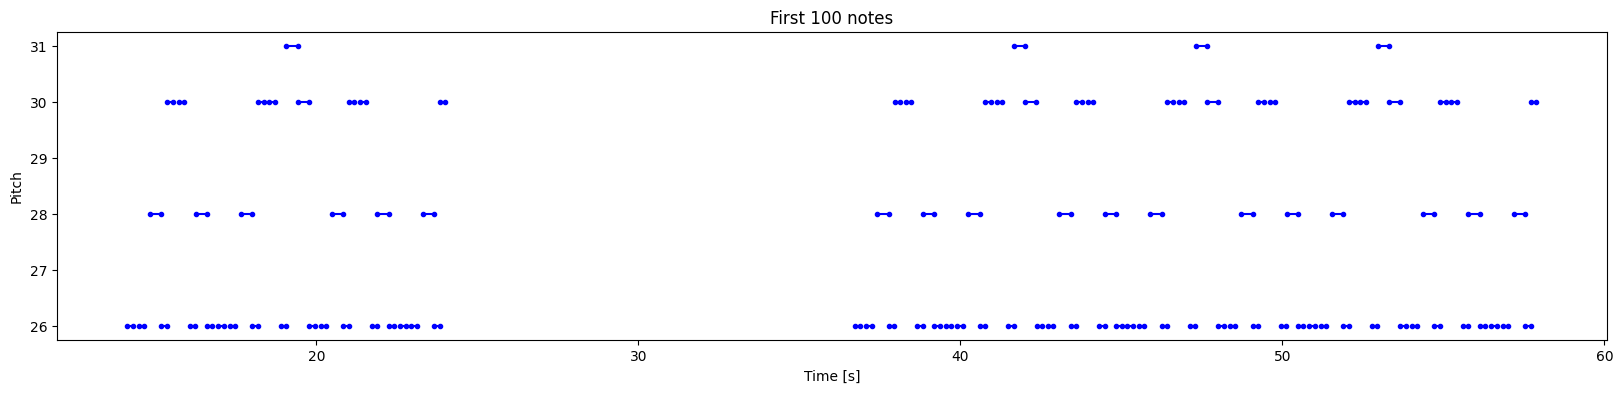

In [22]:
plot_piano_roll(raw_notes, count=100)

Plot the notes for the entire track.

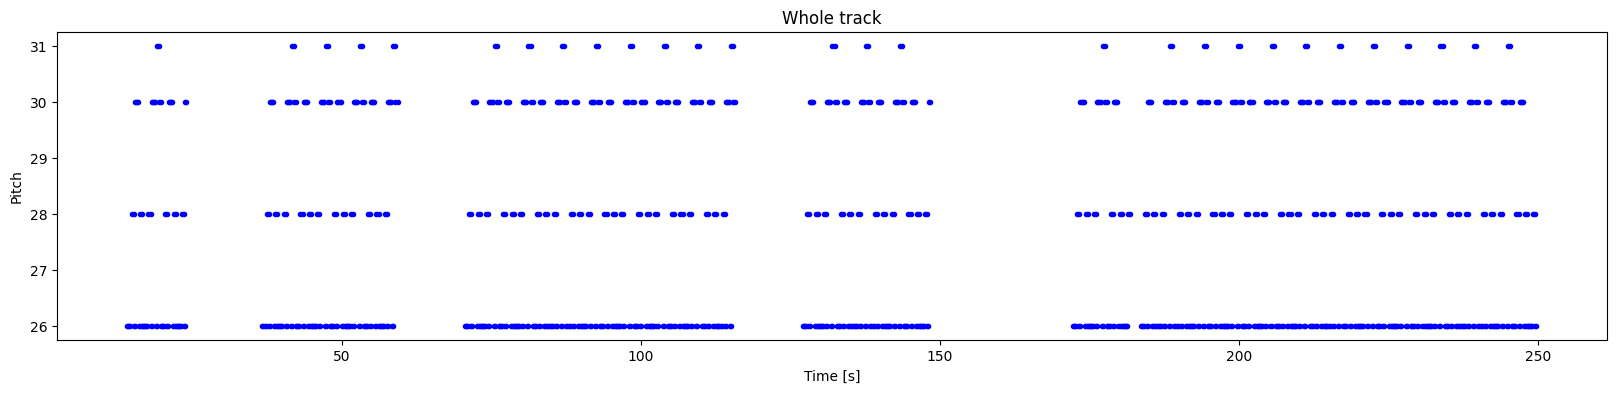

In [23]:
plot_piano_roll(raw_notes)

Check the distribution of each note variable.

In [24]:
def plot_distributions(notes: pd.DataFrame, drop_percentile=2.5):
    plt.figure(figsize=[15, 5])
    plt.subplot(1, 3, 1)
    sns.histplot(notes, x='pitch', bins=20)
    plt.subplot(1, 3, 2)
    max_step = np.percentile(notes['step'], 100 - drop_percentile)
    sns.histplot(notes, x='step', bins=np.linspace(0, max_step, 21))
    plt.subplot(1, 3, 3)
    max_duration = np.percentile(notes['duration'], 100 - drop_percentile)
    sns.histplot(notes, x='duration', bins=np.linspace(0, max_duration, 21))

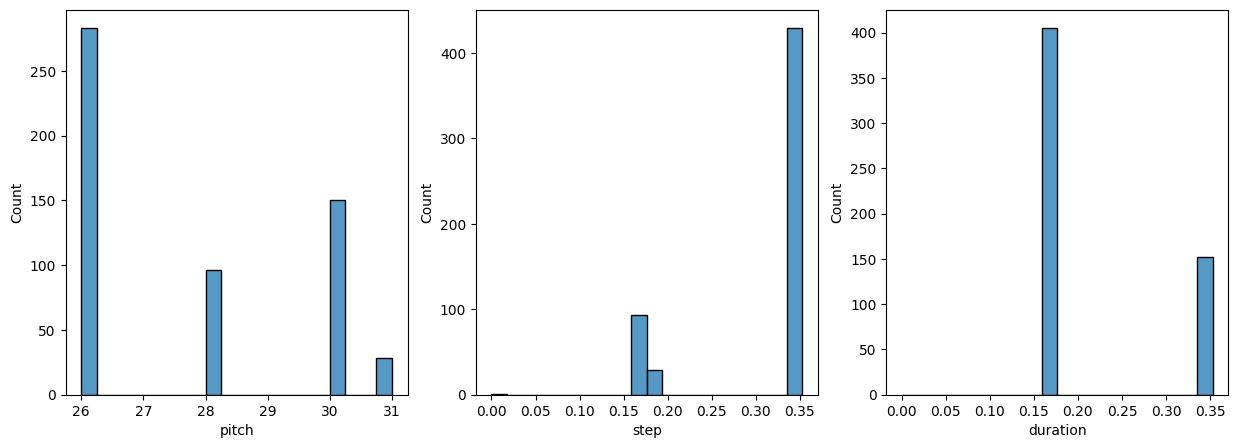

In [25]:
plot_distributions(raw_notes)

###7. Собираем MIDI из нот

In [26]:
def notes_to_midi(
    notes: pd.DataFrame,
    out_file: str,
    program: int = 30,        # 30 = Distortion Guitar, 27 = Clean Guitar, 33 = Bass
    velocity: int = 100,
    with_drums: bool = True,
) -> pretty_midi.PrettyMIDI:
    pm = pretty_midi.PrettyMIDI(initial_tempo=120)
    instrument = pretty_midi.Instrument(program=program)

    prev_start = 0
    for _, note in notes.iterrows():
        start = float(prev_start + note['step'])
        end = float(start + note['duration'])
        instrument.notes.append(pretty_midi.Note(
            velocity=velocity, pitch=int(note['pitch']), start=start, end=end))
        prev_start = start
    pm.instruments.append(instrument)

    # Простой рок-бийт: бочка на 1 и 3, рабочий на 2 и 4
    if with_drums:
        drums = pretty_midi.Instrument(program=0, is_drum=True, name='Rock Drums')
        track_end = notes['end'].max()
        beat = 0.5  # пол-такта в 4/4 при 120 BPM
        t, k, s = 0.0, 36, 38   # GM-номера: бочка и рабочий
        while t < track_end:
            drums.notes.append(pretty_midi.Note(velocity=110, pitch=k, start=t, end=t + 0.2))
            drums.notes.append(pretty_midi.Note(velocity=100, pitch=s, start=t + beat, end=t + beat + 0.2))
            t += 2 * beat
        pm.instruments.append(drums)

    pm.write(out_file)
    return pm

###8. Тренировочный датасет


Create the training dataset by extracting notes from the MIDI files. You can start by using a small number of files, and experiment later with more. This may take a couple minutes.

In [27]:
num_files = 500
all_notes = []
for f in filenames[:num_files]:
    notes = midi_to_notes(f)
    if notes is not None:
        all_notes.append(notes)

/usr/local/lib/python3.13/dist-packages/pretty_midi/pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(


In [28]:
all_notes = pd.concat(all_notes, ignore_index=True)
n_notes = len(all_notes)
print('Number of notes parsed:', n_notes)

Number of notes parsed: 690403


In [29]:
key_order = ['pitch', 'step', 'duration']
train_notes = np.stack([all_notes[key] for key in key_order], axis=1)

In [30]:
notes_ds = tf.data.Dataset.from_tensor_slices(train_notes)

You will train the model on batches of sequences of notes. Each example will consist of a sequence of notes as the input features, and the next note as the label. In this way, the model will be trained to predict the next note in a sequence. You can find a diagram describing this process (and more details) in [Text classification with an RNN](https://www.tensorflow.org/text/tutorials/text_generation).

You can use the handy [window](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#window) function with size `seq_length` to create the features and labels in this format.

In [31]:
def create_sequences(dataset, seq_length, vocab_size=128):
    seq_length = seq_length + 1
    windows = dataset.window(seq_length, shift=1, stride=1, drop_remainder=True)
    flatten = lambda x: x.batch(seq_length, drop_remainder=True)
    sequences = windows.flat_map(flatten)

    def scale_pitch(x):
        return x / [vocab_size, 1.0, 1.0]

    def split_labels(sequences):
        inputs = sequences[:-1]
        labels_dense = sequences[-1]
        labels = {key: labels_dense[i] for i, key in enumerate(key_order)}
        return scale_pitch(inputs), labels

    return sequences.map(split_labels, num_parallel_calls=tf.data.AUTOTUNE)

In [32]:
seq_length = 100
vocab_size = 128
seq_ds = create_sequences(notes_ds, seq_length, vocab_size)

In [33]:
batch_size = 64
buffer_size = n_notes - seq_length
train_ds = (seq_ds
            .shuffle(buffer_size)
            .batch(batch_size, drop_remainder=True)
            .cache()
            .prefetch(tf.data.experimental.AUTOTUNE))

###Создание и обучение модели

The model will have three outputs, one for each note variable. For `step` and `duration`, you will use a custom loss function based on mean squared error that encourages the model to output non-negative values.

In [34]:
def mse_with_positive_pressure(y_true: tf.Tensor, y_pred: tf.Tensor):
  mse = (y_true - y_pred) ** 2
  positive_pressure = 10 * tf.maximum(-y_pred, 0.0)
  return tf.reduce_mean(mse + positive_pressure)

In [35]:
inputs = tf.keras.Input((seq_length, 3))
x = tf.keras.layers.LSTM(128)(inputs)
x = tf.keras.layers.Dropout(0.2)(x)   # немного регуляризации для меньшего датасета

outputs = {
    'pitch': tf.keras.layers.Dense(128, name='pitch')(x),
    'step': tf.keras.layers.Dense(1, name='step')(x),
    'duration': tf.keras.layers.Dense(1, name='duration')(x),
}
model = tf.keras.Model(inputs, outputs)

In [36]:
loss = {
    'pitch': tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    'step': mse_with_positive_pressure,
    'duration': mse_with_positive_pressure,
}
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

In [37]:
model.compile(
    loss=loss,
    loss_weights={'pitch': 0.05, 'step': 1.0, 'duration': 1.0},
    optimizer=optimizer,
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 100, 3)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 128)       │     67,584 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ duration (Dense)    │ (None, 1)         │        129 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pitch (Dense)       │ (None, 128)       │     16,512 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ step (Dense)        │ (None, 1)         │        129 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 84,354 (329.51 KB)

 Trainable params: 84,354 (329.51 KB)

 Non-trainable params: 0 (0.00 B)

Train the model.

In [38]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath='./training_checkpoints/ckpt_{epoch}.weights.h5',
        save_weights_only=True),
    tf.keras.callbacks.EarlyStopping(
        monitor='loss', patience=5, verbose=1, restore_best_weights=True),
]

In [ ]:
%%time
epochs = 50
history = model.fit(train_ds, epochs=epochs, callbacks=callbacks)

Epoch 1/50
   7987/Unknown 1190s 126ms/step - duration_loss: 0.1386 - loss: 0.8224 - pitch_loss: 3.6191 - step_loss: 0.5029

In [2]:
plt.plot(history.epoch, history.history['loss'], label='total loss')
plt.show()

NameError: name 'plt' is not defined

###11. Генерируем трек

In [3]:
def predict_next_note(notes: np.ndarray, model: tf.keras.Model, temperature: float = 1.0):
    """Generates a note as a tuple of (pitch, step, duration)."""
    assert temperature > 0

    inputs = tf.expand_dims(notes, 0)
    predictions = model.predict(inputs, verbose=0)

    pitch_logits = predictions['pitch'] / temperature
    pitch = tf.random.categorical(pitch_logits, num_samples=1)[0, 0]

    step = max(0.0, float(predictions['step'][0, 0]))
    duration = max(0.0, float(predictions['duration'][0, 0]))

    return int(pitch), step, duration

NameError: name 'np' is not defined

Now generate some notes. You can play around with temperature and the starting sequence in `next_notes` and see what happens.

In [51]:
# Тональность отправной фразы, например E-минор (пентатоника рок-музыки)
SCALE_PITCHES = {40, 42, 43, 45, 47, 52, 54, 55, 57, 59,
                 64, 66, 67, 69, 71, 76, 78, 79, 81}  # E minor pentatonic

PITCH_MIN, PITCH_MAX = 40, 84  # диапазон гитары

def snap_to_scale(pitch: int) -> int:
    if PITCH_MIN <= pitch <= PITCH_MAX and pitch in SCALE_PITCHES:
        return pitch
    # сдвигаем ноту к ближайшей ноте гаммы в пределах ±2 полутонов
    best = min(SCALE_PITCHES, key=lambda p: abs(p - pitch) if PITCH_MIN <= p <= PITCH_MAX else 999)
    return best

temperature = 1.0
num_predictions = 300

sample_notes = np.stack([raw_notes[key] for key in key_order], axis=1)
input_notes = sample_notes[:seq_length] / np.array([vocab_size, 1, 1])

generated_notes = []
prev_start = 0
for _ in range(num_predictions):
    pitch, step, duration = predict_next_note(input_notes, model, temperature)
    pitch = snap_to_scale(int(pitch))
    start = prev_start + step
    end = start + duration
    generated_notes.append((pitch, step, duration, start, end))
    input_notes = np.delete(input_notes, 0, axis=0)
    input_notes = np.append(input_notes, np.expand_dims((pitch, step, duration), 0), axis=0)
    prev_start = start

generated_notes = pd.DataFrame(generated_notes, columns=(*key_order, 'start', 'end'))

step_max = np.percentile(all_notes['step'], 97.5)
dur_max = np.percentile(all_notes['duration'], 97.5)

generated_notes['step'] = generated_notes['step'].clip(0, step_max)
generated_notes['duration'] = generated_notes['duration'].clip(0.05, dur_max)

t = 0.0
for i in generated_notes.index:
    t += generated_notes.at[i, 'step']
    generated_notes.at[i, 'start'] = t
    generated_notes.at[i, 'end'] = t + generated_notes.at[i, 'duration']

In [52]:
generated_notes.head(10)

,pitch,step,duration,start,end
0,71,0.140855,0.534798,0.140855,0.675654
1,81,0.776006,2.116694,0.916861,3.033555
2,40,0.778566,2.001119,1.695426,3.696545
3,81,0.796376,2.194756,2.491802,4.686559
4,40,0.813499,1.984635,3.305301,5.289936
5,81,0.808941,2.189258,4.114242,6.303499
6,81,0.815226,1.985087,4.929468,6.914555
7,40,0.804962,1.980672,5.734430,7.715102
8,81,0.797855,2.200486,6.532285,8.732771
9,40,0.807677,1.990419,7.339962,9.330381


###12. Сохраняем и прослушиваем

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

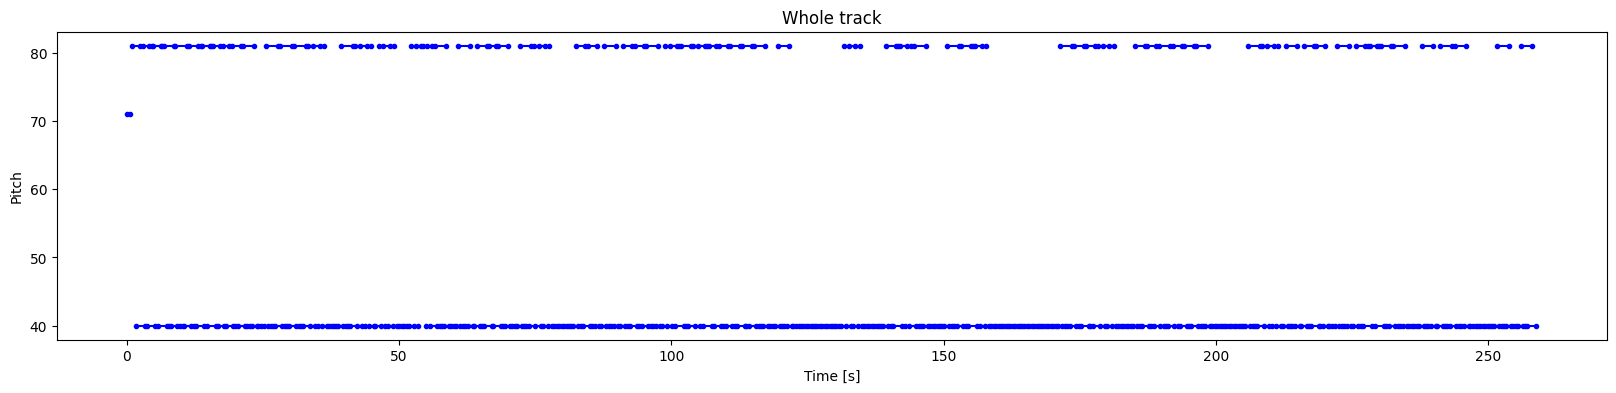

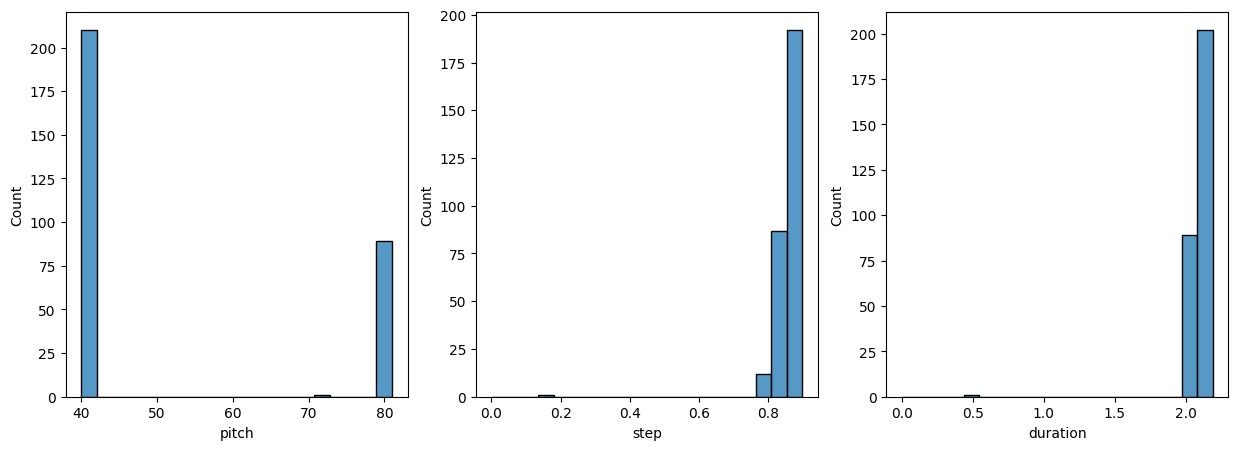

In [53]:
out_file = 'rock.mid'
out_pm = notes_to_midi(generated_notes, out_file=out_file, program=30, with_drums=True)
display_audio(out_pm)

plot_piano_roll(generated_notes)
plot_distributions(generated_notes)

from google.colab import files
files.download(out_file)

In [ ]:
plot_distributions(generated_notes)